##  0. 공통 설정

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import ks_2samp

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3,
                    "font.family": "Malgun Gothic", "axes.unicode_minus": False})
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 50)

# 레포 루트 또는 notebooks/ 어디서 실행해도 data/를 찾음
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA = ROOT / "data"
train = pd.read_csv(DATA / "train.csv.gz", parse_dates=["timestamp"])
test  = pd.read_csv(DATA / "test.csv.gz",  parse_dates=["timestamp"])
subm  = pd.read_csv(DATA / "sample_submission.csv")

TARGET = "target_maxrise_6h"
LAGS  = [1, 3, 6, 12, 24]
WL    = ["wl_t"] + [f"wl_t_minus_{k}h" for k in LAGS]
IMERG = ["imerg_rain_1h", "imerg_rain_6h", "imerg_rain_24h"]
SFC   = ["sfc_rain_1h", "sfc_rain_6h", "sfc_rain_24h"]          # 단위 미확인 → 상대값 취급
RADAR = ["radar_reflectivity_mean", "radar_reflectivity_p95", "radar_reflectivity_ge20_fraction"]
BASIN = ["cat_area", "wsarea", "mean_elevation", "mean_slope", "urban_ratio", "forest_ratio", "stream_order"]
FEATS = WL + IMERG + SFC + RADAR + BASIN

# README 명세 검증
assert train.shape == (749_657, 26) and test.shape == (186_263, 25)
assert train.isna().sum().sum() == 0 and test.isna().sum().sum() == 0
assert not train.duplicated(["station_id", "timestamp"]).any()
assert not test.duplicated(["station_id", "timestamp"]).any()
assert set(subm.row_id) == set(test.row_id) and len(subm) == len(test)
assert set(train.station_id) == set(test.station_id)
print("관측소:", train.station_id.nunique(), "| 명세 검증 통과")

# 행 순서가 섞여 있으므로 정렬 필수
train = train.sort_values(["station_id", "timestamp"]).reset_index(drop=True)
test  = test.sort_values(["station_id", "timestamp"]).reset_index(drop=True)
y = train[TARGET]

------------------------

## 1단계 - 데이터 구조 및 품질 확인

- 본격적인 분석에 앞서 Train/Test 데이터의 크기, 변수 구성, 결측치 및 중복 여부를 확인하는 작업
- 수위·강우·레이더 등 주요 변수의 값 범위를 확인하여 데이터에 비정상적인 값이 존재하는지 점검

### 1-1. 데이터 기본 구조 확인
- Train/Test 데이터의 크기와 변수 구성을 확인하고, 관측소 수와 기본적인 데이터 품질을 점검

In [8]:
print("=== 데이터 크기 ===")
print("Train :", train.shape)
print("Test  :", test.shape)

print("\n=== 관측소 수 ===")
print("Train :", train["station_id"].nunique())
print("Test  :", test["station_id"].nunique())

print("\n=== 결측치 개수 ===")
print("Train :", train.isnull().sum().sum())
print("Test  :", test.isnull().sum().sum())

print("\n=== 중복 행 개수 ===")
print("Train :", train.duplicated().sum())
print("Test  :", test.duplicated().sum())

=== 데이터 크기 ===
Train : (749657, 28)
Test  : (186263, 27)

=== 관측소 수 ===
Train : 465
Test  : 465

=== 결측치 개수 ===
Train : 0
Test  : 0

=== 중복 행 개수 ===
Train : 0
Test  : 0


데이터 크기와 수 정확하고, 결측치 중복도 없음을 확인 

### 1-2. 변수 종류 확인
- 제공된 변수를 수위, 강우, 레이더, 유역환경 정보로 구분하여 이후 분석에서 사용할 변수 구조를 확인

In [9]:
WL = [
    "wl_t",
    "wl_t_minus_1h",
    "wl_t_minus_3h",
    "wl_t_minus_6h",
    "wl_t_minus_12h",
    "wl_t_minus_24h"
]

IMERG = [
    "imerg_rain_1h",
    "imerg_rain_6h",
    "imerg_rain_24h"
]

SFC = [
    "sfc_rain_1h",
    "sfc_rain_6h",
    "sfc_rain_24h"
]

RADAR = [
    "radar_reflectivity_mean",
    "radar_reflectivity_p95",
    "radar_reflectivity_ge20_fraction"
]

BASIN = [
    "cat_area",
    "wsarea",
    "mean_elevation",
    "mean_slope",
    "urban_ratio",
    "forest_ratio",
    "stream_order"
]

TARGET = "target_maxrise_6h"

### 1-3. 주요 변수의 값 범위 확인
- 주요 변수의 최솟값과 최댓값을 확인하여 음수 강우량이나 비정상적으로 큰 값 등 데이터 이상 여부를 확인

In [10]:
check_cols = WL + IMERG + SFC + RADAR + BASIN

summary = train[check_cols].describe().T[
    ["min", "mean", "50%", "max"]
]

display(summary)

,min,mean,50%,max
wl_t,-3.8400,4.059135,1.1300,139.6400
wl_t_minus_1h,-3.9000,4.051839,1.1200,139.6900
wl_t_minus_3h,-3.9000,4.038830,1.1100,139.7500
wl_t_minus_6h,-3.8100,4.023965,1.1000,139.9000
wl_t_minus_12h,-3.9100,4.008545,1.0800,140.1400
wl_t_minus_24h,-3.9000,3.995167,1.0600,140.5800
imerg_rain_1h,0.0000,1.396494,0.2270,114.5300
imerg_rain_6h,0.0000,7.597034,2.5410,313.5570
imerg_rain_24h,0.0000,18.236092,7.6290,371.2280
sfc_rain_1h,0.0000,1.194352,0.0000,87.0000


전체적으로 변수 범위를 보면 강우량, 레이더 비율, 유역환경 변수에서 바로 보이는 비정상적인 값은 없음.

다만 분포가 한쪽으로 치우친 변수들이 보임
- imerg_rain_6h: 중앙값 약 2.54, 최대 313.56
- sfc_rain_6h: 중앙값 0.5, 최대 290.5
- wsarea: 중앙값 약 115, 최대 약 29,688

즉 대부분의 데이터는 작은 값에 몰려 있는데, 일부 호우나 일부 유역에서 매우 큰 값이 존재하는 형태


<주요 변수에서 명확한 비정상 범위는 확인되지 않았다. 다만 강우량과 유역면적은 대부분 작은 값에 집중되어 있으면서 일부 큰 값을 가지는 치우친 분포를 보였다.>

### 1-4. 강우 데이터 기본 점검
- 강우량에 음수 값이 존재하는지 확인하고, 1시간·6시간·24시간 누적강우량이 시간 범위에 따라 정상적으로 누적되는지 확인

정상적인 누적강우는 기본적으로 1시간 강우 ≤ 6시간 강우 ≤ 24시간 강우 이런형태

In [11]:
for name, df in [("Train", train), ("Test", test)]:
    
    print(f"\n=== {name} ===")
    
    # 음수 강우 확인
    rain_cols = IMERG + SFC
    
    negative = (df[rain_cols] < 0).sum()
    
    print("음수 강우 개수")
    print(negative[negative > 0])

    # IMERG 누적 관계 확인
    imerg_error = (
        (df["imerg_rain_1h"] > df["imerg_rain_6h"]) |
        (df["imerg_rain_6h"] > df["imerg_rain_24h"])
    ).sum()

    # SFC 누적 관계 확인
    sfc_error = (
        (df["sfc_rain_1h"] > df["sfc_rain_6h"]) |
        (df["sfc_rain_6h"] > df["sfc_rain_24h"])
    ).sum()

    print("IMERG 누적 관계 오류 :", imerg_error)
    print("SFC 누적 관계 오류   :", sfc_error)


=== Train ===
음수 강우 개수
Series([], dtype: int64)
IMERG 누적 관계 오류 : 0
SFC 누적 관계 오류   : 0

=== Test ===
음수 강우 개수
Series([], dtype: int64)
IMERG 누적 관계 오류 : 0
SFC 누적 관계 오류   : 0


결론 : 강우 변수에서 음수 값은 확인되지 않았으며, 1시간·6시간·24시간 누적강우량의 크기 관계도 모두 정상

### 1-5. 레이더 변수 범위 확인
- 레이더 변수의 값 범위와 분포를 확인하여 특정 값에 데이터가 과도하게 집중되어 있는지 살펴봄

In [12]:
display(
    train[RADAR].describe().T[
        ["min", "mean", "50%", "max"]
    ]
)

,min,mean,50%,max
radar_reflectivity_mean,0.0,13.484527,13.0350,55.917
radar_reflectivity_p95,0.0,19.832657,21.9700,67.770
radar_reflectivity_ge20_fraction,0.0,0.340483,0.1113,1.000


In [13]:
# ge20_fraction은 0~1 사이 값이 나와야 함
print(
    "ge20_fraction 범위:",
    train["radar_reflectivity_ge20_fraction"].min(),
    "~",
    train["radar_reflectivity_ge20_fraction"].max()
)

ge20_fraction 범위: 0.0 ~ 1.0


radar_reflectivity_ge20_fraction은 0~1 범위에 위치하여 비율 변수의 범위에 부합함을 확인

### 1-6. Train과 Test 기본 분포 비교
- Train과 Test 데이터가 서로 크게 다른 특성을 가지는지 확인하기 위해 주요 변수의 분포를 비교

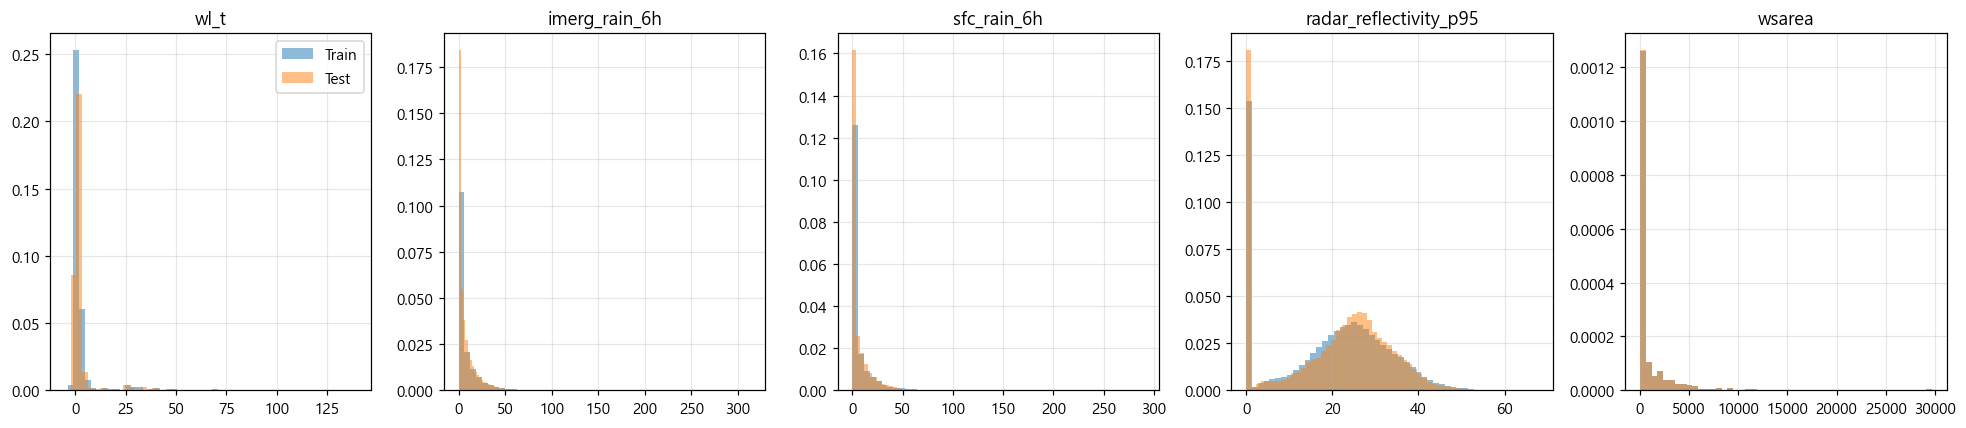

In [14]:
compare_cols = [
    "wl_t",
    "imerg_rain_6h",
    "sfc_rain_6h",
    "radar_reflectivity_p95",
    "wsarea"
]

fig, axes = plt.subplots(
    1, len(compare_cols),
    figsize=(18, 4)
)

for ax, col in zip(axes, compare_cols):

    ax.hist(
        train[col],
        bins=50,
        alpha=0.5,
        density=True,
        label="Train"
    )

    ax.hist(
        test[col],
        bins=50,
        alpha=0.5,
        density=True,
        label="Test"
    )

    ax.set_title(col)

axes[0].legend()

plt.tight_layout()
plt.show()

파란색(train)과 주황색(test)가 비슷하게 겹치는가?를 확인

많이 겹친다 -> train/test 환경이 비교적 비슷함 을 확인


#### 1단계 결론
: 데이터 품질 확인 결과, Train/Test 모두 결측치와 중복값이 없었으며 강우 누적값 또한 정상적인 관계를 보였다. 주요 변수에서도 뚜렷한 비정상 범위는 확인되지 않았다. 또한 현재 수위, 강우량, 레이더, 유역면적의 Train/Test 분포가 전반적으로 유사하게 나타나, 주요 입력변수 수준에서 큰 분포 차이는 확인되지 않았다.

----------------------------

## 2단계 — 타깃 및 주요 변수와의 관계 확인

### 2-1. 타깃 분포 확인
- 향후 6시간 최대 수위 상승량의 분포를 확인하여 일반적인 수위 변화와 큰 상승이 발생하는 구간의 특성을 살펴보자

count    749657.000000
mean          0.108976
std           0.395378
min          -8.740000
25%           0.000000
50%           0.010000
75%           0.070000
max           8.300000
Name: target_maxrise_6h, dtype: float64


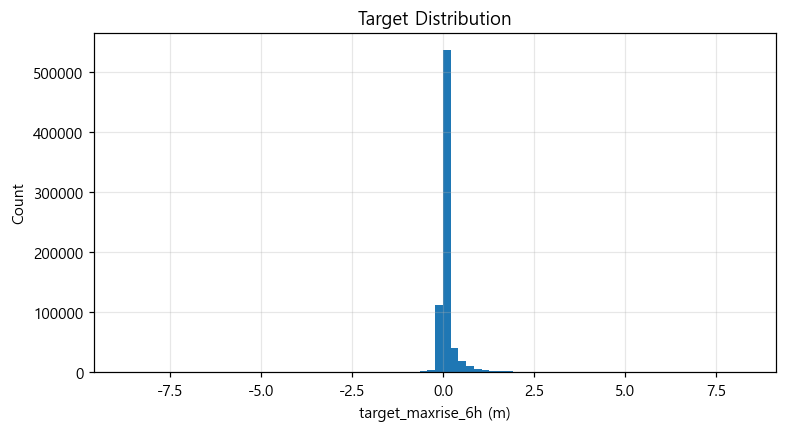

In [15]:
TARGET = "target_maxrise_6h"

print(train[TARGET].describe())

plt.figure(figsize=(8, 4))

plt.hist(
    train[TARGET],
    bins=80
)

plt.title("Target Distribution")
plt.xlabel("target_maxrise_6h (m)")
plt.ylabel("Count")

plt.show()

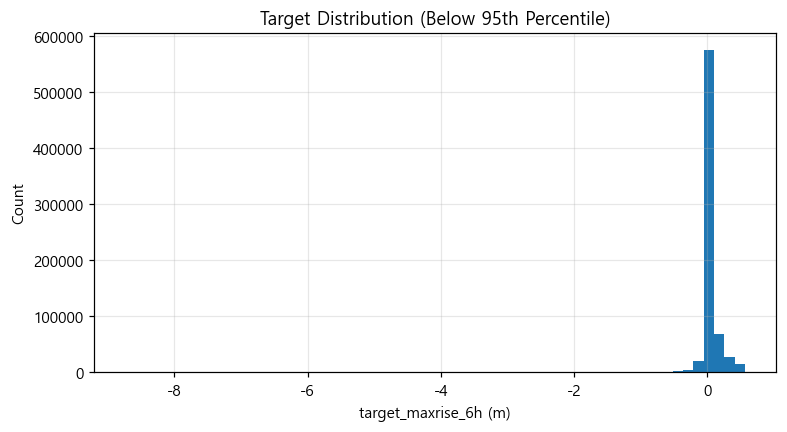

95% 분위수: 0.57
음수 비율: 0.15881529819637513
0 이상 비율: 0.8411847018036248


In [16]:
upper = train[TARGET].quantile(0.95)

plt.figure(figsize=(8, 4))

plt.hist(
    train.loc[train[TARGET] <= upper, TARGET],
    bins=60
)

plt.title("Target Distribution (Below 95th Percentile)")
plt.xlabel("target_maxrise_6h (m)")
plt.ylabel("Count")

plt.show()

print("95% 분위수:", upper)
print("음수 비율:", (train[TARGET] < 0).mean())
print("0 이상 비율:", (train[TARGET] >= 0).mean())

결과값 : 타깃은 대부분 작은데 일부만 엄청 큼
- 평균: 0.109m
- 중앙값: 0.01m
- 75%: 0.07m
- 95%: 0.57m
- 최소: -8.74m
- 최대: 8.30m
- 음수: 약 15.9%

즉, 대부분의 경우 수위 변화가 크지 않지만, 아주 일부 상황에서 큰 상승·하강이 발생하는 구조

=> RMSE에서는 이 극단적인 몇 개 사례를 잘 맞히는 게 중요할 가능성이 높아보임

### 2-2. 최근 수위 변화와 향후 수위 상승
- 현재 수위와 과거 수위의 차이를 이용하여 최근 수위의 상승·하강 추세가 향후 6시간 최대 수위 상승량과 관련이 있는지 확인

In [27]:
train["wl_change_1h"] = (
    train["wl_t"] - train["wl_t_minus_1h"]
)

train["wl_change_3h"] = (
    train["wl_t"] - train["wl_t_minus_3h"]
)

train["wl_change_6h"] = (
    train["wl_t"] - train["wl_t_minus_6h"]
)

train["wl_change_12h"] = (
    train["wl_t"] - train["wl_t_minus_12h"]
)

train["wl_change_24h"] = (
    train["wl_t"] - train["wl_t_minus_24h"]
)

In [26]:
# 타깃과 상관관계부터 확인 
wl_change_cols = [
    "wl_change_1h",
    "wl_change_3h",
    "wl_change_6h",
    "wl_change_12h",
    "wl_change_24h"
]

wl_corr = (
    train[wl_change_cols + [TARGET]]
    .corr()[TARGET]
    .drop(TARGET)
    .sort_values(ascending=False)
)

display(wl_corr.to_frame("correlation"))

,correlation
wl_change_1h,0.187955
wl_change_12h,0.091775
wl_change_24h,0.067696
wl_change_3h,-0.042401
wl_change_6h,-0.306253


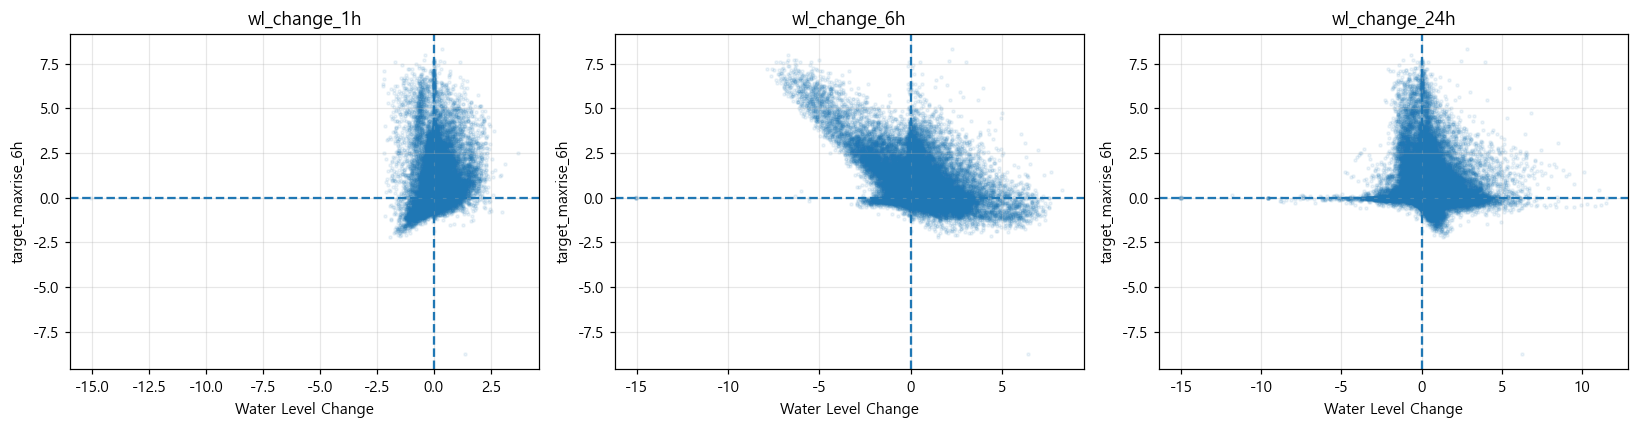

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(
    axes,
    ["wl_change_1h", "wl_change_6h", "wl_change_24h"]
):
    
    ax.scatter(
        train[col],
        train[TARGET],
        s=4,
        alpha=0.08
    )
    
    ax.axvline(0, linestyle="--")
    ax.axhline(0, linestyle="--")
    
    ax.set_title(col)
    ax.set_xlabel("Water Level Change")
    ax.set_ylabel(TARGET)

plt.tight_layout()
plt.show()

### 2-3. 강우량과 수위 상승의 관계
- 최근 1시간·6시간·24시간 강우량과 향후 수위 상승량의 관계를 비교하여 어떤 시간범위의 강우가 수위 상승과 더 관련이 있는지 확인

In [21]:
#상관관계
rain_cols = [
    "imerg_rain_1h",
    "imerg_rain_6h",
    "imerg_rain_24h",
    "sfc_rain_1h",
    "sfc_rain_6h",
    "sfc_rain_24h"
]

rain_corr = (
    train[rain_cols + [TARGET]]
    .corr()[TARGET]
    .drop(TARGET)
    .sort_values(ascending=False)
)

display(rain_corr.to_frame("correlation"))

,correlation
sfc_rain_1h,0.255799
sfc_rain_6h,0.241308
imerg_rain_6h,0.196708
imerg_rain_1h,0.191097
sfc_rain_24h,0.188610
imerg_rain_24h,0.161628


=> 지상강우(sfc)가 IMERG보다 조금 더 강한 관계를 보이고 있고, 특히 최근 1시간 강우가 제일 높음

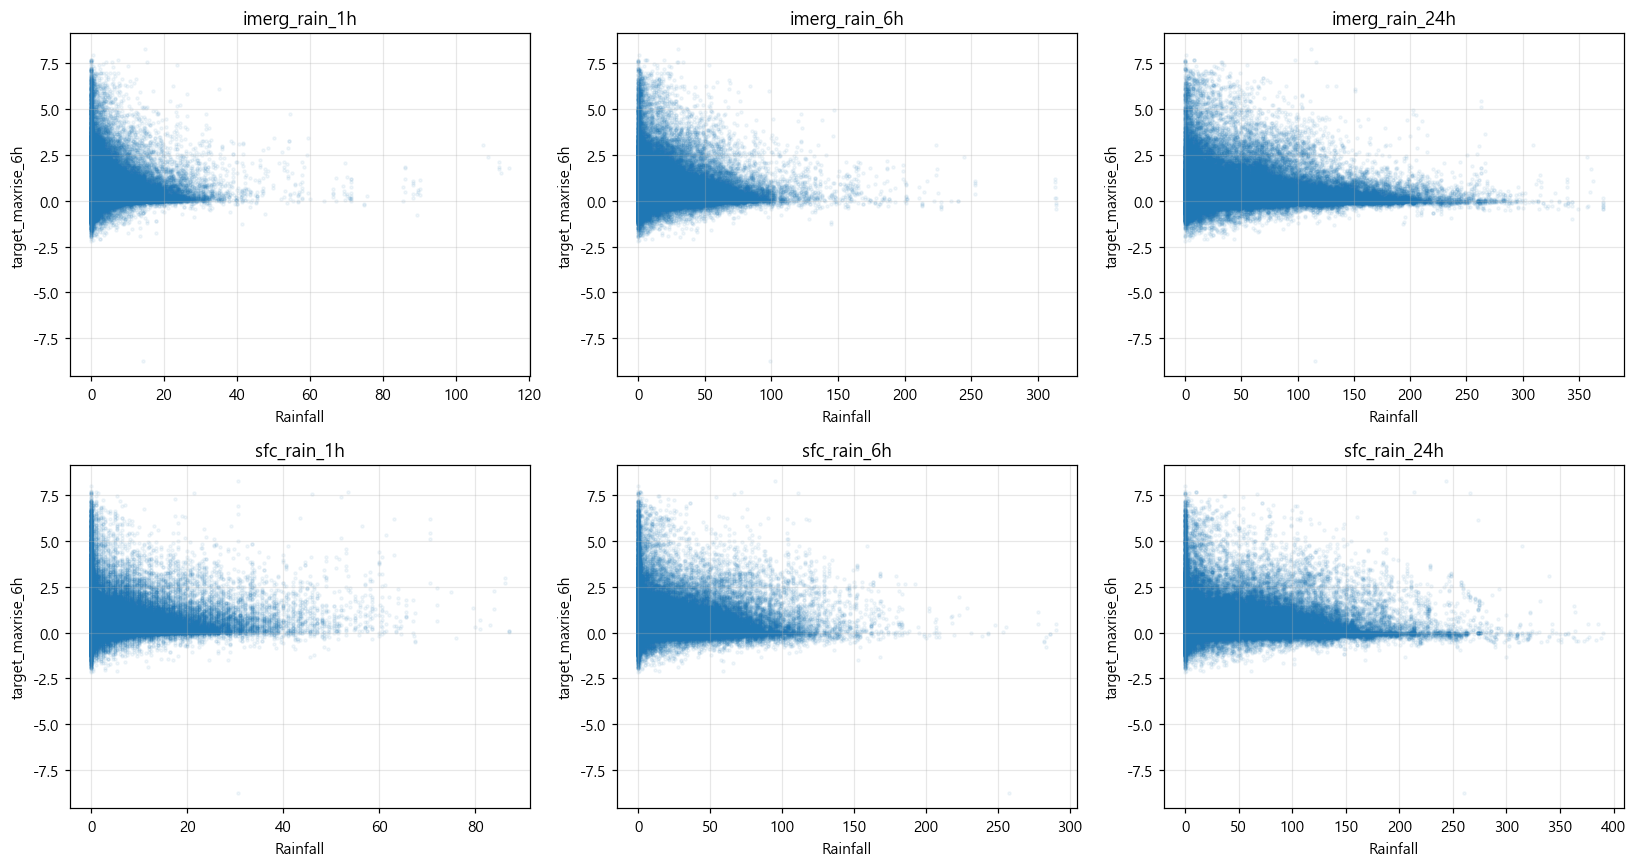

In [22]:
# 시간범위별로 시각화
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, col in zip(axes.flat, rain_cols):
    
    ax.scatter(
        train[col],
        train[TARGET],
        s=4,
        alpha=0.06
    )
    
    ax.set_title(col)
    ax.set_xlabel("Rainfall")
    ax.set_ylabel(TARGET)

plt.tight_layout()
plt.show()

산점도로 봐선 같은 강우량이라도 타깃이 엄청 퍼져있어 비 많이 옴 -> 무조건 수위 많이 상승
이라는 해석은 불가
- 강우량만으로 설명하기보다는 현재 수위 흐름 + 강우 시점 + 유역 특성을 같이 봐야 할 가능성이 크다.

### 2-4. 현재 수위 자체와 타깃 관계 확인
- 현재 절대수위와 향후 수위 상승량의 관계를 확인하여 수위 자체보다 최근 수위 변화량이 더 유용한 정보인지 비교

In [23]:
water_cols = [
    "wl_t",
    "wl_t_minus_1h",
    "wl_t_minus_3h",
    "wl_t_minus_6h",
    "wl_t_minus_12h",
    "wl_t_minus_24h"
]

water_corr = (
    train[water_cols + [TARGET]]
    .corr()[TARGET]
    .drop(TARGET)
    .sort_values(ascending=False)
)

display(water_corr.to_frame("correlation"))

,correlation
wl_t_minus_6h,-0.022003
wl_t_minus_3h,-0.031002
wl_t,-0.031970
wl_t_minus_1h,-0.033722
wl_t_minus_24h,-0.034184
wl_t_minus_12h,-0.034421


In [24]:
# 절대수위 vs 수위변화량 비교
compare = (
    train[
        water_cols
        + wl_change_cols
        + [TARGET]
    ]
    .corr()[TARGET]
    .drop(TARGET)
    .sort_values(ascending=False)
)

display(compare.to_frame("correlation"))

,correlation
wl_change_1h,0.187955
wl_change_12h,0.091775
wl_change_24h,0.067696
wl_t_minus_6h,-0.022003
wl_t_minus_3h,-0.031002
wl_t,-0.031970
wl_t_minus_1h,-0.033722
wl_t_minus_24h,-0.034184
wl_t_minus_12h,-0.034421
wl_change_3h,-0.042401


2-5. 주요 변수 상관관계 한 번에 정리

In [25]:
main_cols = (
    water_cols
    + wl_change_cols
    + rain_cols
    + [
        "radar_reflectivity_mean",
        "radar_reflectivity_p95",
        "radar_reflectivity_ge20_fraction",
        "wsarea",
        "cat_area",
        "mean_elevation",
        "mean_slope",
        "urban_ratio",
        "forest_ratio",
        "stream_order"
    ]
)

target_corr = (
    train[main_cols + [TARGET]]
    .corr()[TARGET]
    .drop(TARGET)
    .sort_values(ascending=False)
)

display(target_corr.to_frame("correlation"))

,correlation
sfc_rain_1h,0.255799
sfc_rain_6h,0.241308
imerg_rain_6h,0.196708
imerg_rain_1h,0.191097
sfc_rain_24h,0.188610
radar_reflectivity_mean,0.188057
wl_change_1h,0.187955
radar_reflectivity_p95,0.176602
radar_reflectivity_ge20_fraction,0.175044
imerg_rain_24h,0.161628


유역환경 변수는 단독으로는 거의 관계가 없음
- wsarea: 0.022 / cat_area: 0.031 / stream_order: 0.008 / urban_ratio: 0.039  / forest_ratio: -0.064

하지만 우리가 원래 보고 싶은 건 큰 유역과 작은 유역에서 강우에 반응하는 방식이 다른가? 이기 때문에
wsarea → target 직접 관계가 아니라
wsarea × rainfall → target
을 봐야 함

____________________________

1. 절대수위와 타깃 상관은 전부 거의 0임
- wl_t: -0.032 / wl_t_minus_1h: -0.034 / wl_t_minus_6h: -0.022
2. 수위 변화량은 
- 최근 1시간 변화: +0.188
- 최근 6시간 변화: -0.306

즉 현재 수위가 몇 m인가보다 최근에 **최근에 수위가 어떻게 움직이고 있었는가**가 더 중요해보임

=> 수위 차분 변수를 쓰려던 방향과 꽤 잘 맞음

3. wl_change_6h = -0.306은 꼭 더 봐야 함
- wl_change_6h = 현재 수위 - 6시간 전 수위 
이므로 값이 크면 최근 6시간 동안 이미 많이 상승했다는 근거인데 
- 오히려 앞으로 6시간 상승량은 작아지는 경향을 보임 = -0.3

=> 이미 지난 6시간 동안 크게 오른 경우에는 호우에 따른 상승이 상당 부분 진행된 상태라, 앞으로 추가 상승할 폭이 작아질 수 있다. 라는 결론과 비슷

__________________________________

### 추가 검증 ①
#### 수위 변화 관계가 이상치 때문에 나온 건지 확인
- Pearson 상관계수는 극단값의 영향을 받을 수 있으므로 Spearman 상관계수와 비교하여 수위 변화량과 타깃 간 관계가 안정적으로 나타나는지 확인

In [28]:
from scipy.stats import spearmanr

check_cols = [
    "wl_change_1h",
    "wl_change_3h",
    "wl_change_6h",
    "wl_change_12h",
    "wl_change_24h"
]

result = []

for col in check_cols:
    
    pearson = train[col].corr(train[TARGET])
    spearman = spearmanr(train[col], train[TARGET]).statistic
    
    result.append({
        "variable": col,
        "pearson": pearson,
        "spearman": spearman
    })

display(pd.DataFrame(result))

,variable,pearson,spearman
0,wl_change_1h,0.187955,0.390924
1,wl_change_3h,-0.042401,0.330059
2,wl_change_6h,-0.306253,0.223832
3,wl_change_12h,0.091775,0.191115
4,wl_change_24h,0.067696,0.132845


- 최근 수위 변화량은 향후 수위 상승과 관련이 있으나, 단순한 직선 관계는 아니다. 특히 6시간 변화량은 큰 상승뿐 아니라 큰 하강 구간에서도 이후 큰 수위 상승이 나타나는 비선형 패턴을 보

=> 나중에 모델에 - wl_change_6h /  abs(wl_change_6h) /  상승/하강 여부

같은 변수를 넣어볼 이유가 생김

## 추가 검증 ②
### wl_change_6h를 구간으로 나눠서 직접 보기
- 최근 6시간 수위 변화량을 구간별로 나누어 실제로 수위 변화 방향에 따라 향후 최대 상승량이 어떻게 달라지는지 확인

In [29]:
temp = train[["wl_change_6h", TARGET]].copy()

temp["change_group"] = pd.qcut(
    temp["wl_change_6h"],
    q=10,
    duplicates="drop"
)

change_summary = (
    temp.groupby("change_group", observed=True)
    .agg(
        wl_change_6h=("wl_change_6h", "mean"),
        target_mean=(TARGET, "mean"),
        target_median=(TARGET, "median"),
        count=(TARGET, "size")
    )
    .reset_index(drop=True)
)

display(change_summary)

,wl_change_6h,target_mean,target_median,count
0,-0.426552,0.314256,0.00,75474
1,-0.037620,0.062948,0.00,94717
2,-0.011175,0.041037,0.00,70225
3,-0.000727,0.029444,0.00,201207
4,0.010000,0.039592,0.01,8748
5,0.013892,0.059248,0.02,89506
6,0.037488,0.090852,0.04,60099
7,0.096975,0.152802,0.06,74884
8,0.697985,0.276164,0.10,74797


Text(0.5, 1.0, '최근 6시간 수위 변화와 향후 상승량')

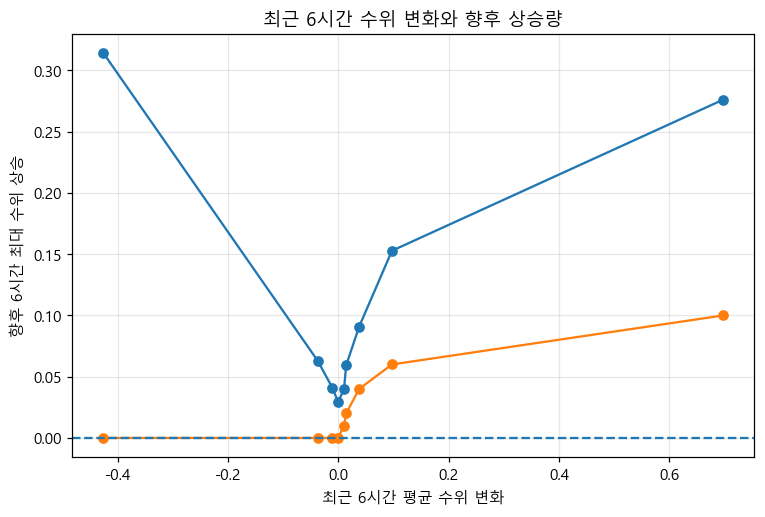

In [30]:
#그래프
plt.figure(figsize=(8, 5))

plt.plot(
    change_summary["wl_change_6h"],
    change_summary["target_mean"],
    marker="o",
    label="Mean"
)

plt.plot(
    change_summary["wl_change_6h"],
    change_summary["target_median"],
    marker="o",
    label="Median"
)

plt.axhline(0, linestyle="--")

plt.xlabel("최근 6시간 평균 수위 변화")
plt.ylabel("향후 6시간 최대 수위 상승")
plt.title("최근 6시간 수위 변화와 향후 상승량")

## 추가 검증 ③
### 누적강우를 실제 시간구간으로 분리
- 누적강우 변수 간 시간범위가 서로 중복되므로, 강우량을 겹치지 않는 시간구간으로 분리하여 어느 시점의 강우가 향후 수위 상승과 더 관련되는지 확인

In [31]:
# IMERG
train["imerg_recent_1h"] = train["imerg_rain_1h"]

train["imerg_prev_1_6h"] = (
    train["imerg_rain_6h"]
    - train["imerg_rain_1h"]
)

train["imerg_prev_6_24h"] = (
    train["imerg_rain_24h"]
    - train["imerg_rain_6h"]
)

# SFC
train["sfc_recent_1h"] = train["sfc_rain_1h"]

train["sfc_prev_1_6h"] = (
    train["sfc_rain_6h"]
    - train["sfc_rain_1h"]
)

train["sfc_prev_6_24h"] = (
    train["sfc_rain_24h"]
    - train["sfc_rain_6h"]
)

In [32]:
#상관관계
rain_interval_cols = [
    "imerg_recent_1h",
    "imerg_prev_1_6h",
    "imerg_prev_6_24h",
    "sfc_recent_1h",
    "sfc_prev_1_6h",
    "sfc_prev_6_24h"
]

interval_corr = (
    train[rain_interval_cols + [TARGET]]
    .corr()[TARGET]
    .drop(TARGET)
    .sort_values(ascending=False)
)

display(interval_corr.to_frame("correlation"))

,correlation
sfc_recent_1h,0.255799
sfc_prev_1_6h,0.202601
imerg_recent_1h,0.191097
imerg_prev_1_6h,0.175695
sfc_prev_6_24h,0.100112
imerg_prev_6_24h,0.096235


SFC / IMERG 둘 다 똑같이 현재 시점에 가까운 강우일수록 향후 수위 상승과 관계가 강하다

=> 전체적으로는 SFC 강우가 IMERG보다 타깃과 더 강한 관계